In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Dataset:
   StudentID  Age  Gender  Ethnicity  ParentalEducation  StudyTimeWeekly  \
0       1001   17       1          0                  2        19.833723   
1       1002   18       0          0                  1        15.408756   
2       1003   15       0          2                  3         4.210570   
3       1004   17       1          0                  3        10.028829   
4       1005   17       1          0                  2         4.672495   

   Absences  Tutoring  ParentalSupport  Extracurricular  Sports  Music  \
0         7         1                2                0       0      1   
1         0         0                1                0       0      0   
2        26         0                2                0       0      0   
3        14         0                3                1       0      0   
4        17         1                3                0       0      0   

   Volunteering       GPA  GradeClass  
0             0  2.929196         2.0  
1        

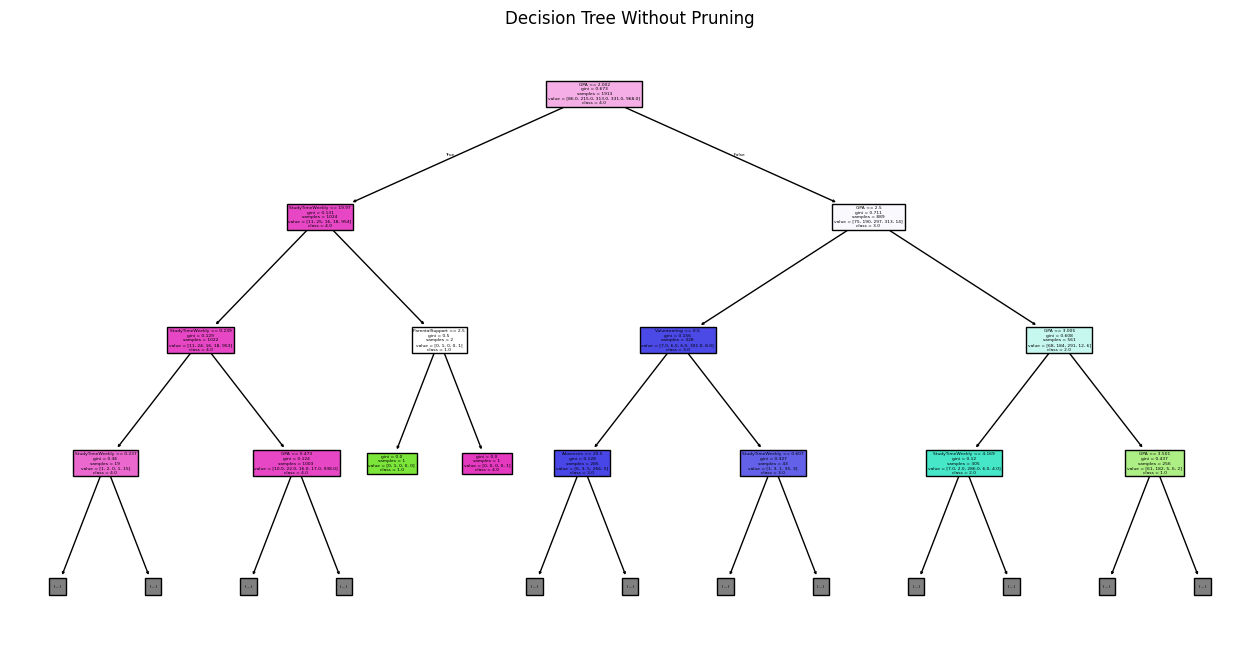

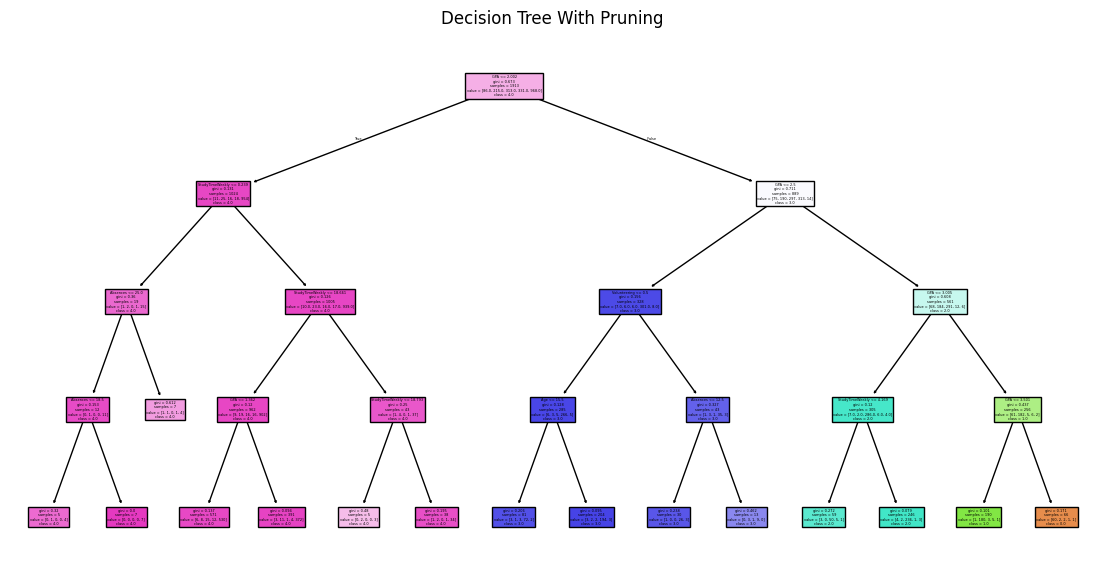


Model Accuracy:
Without Pruning: 86.85 %
With Pruning: 92.48 %

Feature Importance:
GPA                  0.994335
StudyTimeWeekly      0.002842
Absences             0.001796
Volunteering         0.000737
Age                  0.000290
ParentalEducation    0.000000
Ethnicity            0.000000
Gender               0.000000
Tutoring             0.000000
Extracurricular      0.000000
ParentalSupport      0.000000
Music                0.000000
Sports               0.000000
dtype: float64


In [3]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Load dataset
df = pd.read_csv("/content/drive/MyDrive/ML_LAB/Student_performance_data _.csv")

print("Dataset:")
print(df.head())

# Remove student ID because it is not useful for prediction
df = df.drop("StudentID", axis=1)

# Separate features and target
X = df.drop("GradeClass", axis=1)
y = df["GradeClass"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Decision Tree without pruning
tree1 = DecisionTreeClassifier(random_state=42)
tree1.fit(X_train, y_train)

pred1 = tree1.predict(X_test)
accuracy1 = accuracy_score(y_test, pred1)

# Visualize the unpruned tree (first 3 levels)
plt.figure(figsize=(16, 8))
plot_tree(
    tree1,
    feature_names=X.columns,
    class_names=[str(c) for c in tree1.classes_],
    filled=True,
    max_depth=3
)
plt.title("Decision Tree Without Pruning")
plt.show()

# Decision Tree with pruning
tree2 = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)
tree2.fit(X_train, y_train)

pred2 = tree2.predict(X_test)
accuracy2 = accuracy_score(y_test, pred2)

# Visualize the pruned tree
plt.figure(figsize=(14, 7))
plot_tree(
    tree2,
    feature_names=X.columns,
    class_names=[str(c) for c in tree2.classes_],
    filled=True
)
plt.title("Decision Tree With Pruning")
plt.show()

# Compare accuracy
print("\nModel Accuracy:")
print("Without Pruning:", round(accuracy1 * 100, 2), "%")
print("With Pruning:", round(accuracy2 * 100, 2), "%")

# Display feature importance
print("\nFeature Importance:")
importance = pd.Series(
    tree2.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)
